# Автор решения: Иванова Виктория

In [33]:
import math
from scipy import stats
from scipy . stats import norm
import numpy as np

# Задание 1

**Гипотеза H0**: истинное среднее время на карточке вакансии равно 120 секунд, т.е. $\mu = 120$.

Стандартная ошибка среднего:

$$SE(\bar x) = \frac{\sigma}{\sqrt n} = \frac{25}{\sqrt{100}} = 2{,}5 \text{ с}$$
Оценка ушла от 120 на **1,6** стандартной ошибки:
$$z = \frac{\bar x - \mu_0}{SE(\bar x)} = \frac{124 - 120}{2{,}5} = 1{,}6$$

Проверим гипотезу с помощью z-теста:

In [20]:
mu0, n, x_bar, sigma = 120, 100, 124, 25
alpha = 0.05

se = sigma / math.sqrt(n)
z = (x_bar - mu0) / se
p_value = 2 * norm.sf(abs(z))
ci = (x_bar - norm.ppf(1 - alpha/2) * se, x_bar + norm.ppf(1 - alpha/2) * se)

print(f"z = {z:.2f}, p-value = {p_value:.4f}")
print(f"95% CI: [{ci[0]:.1f}; {ci[1]:.1f}]")

z = 1.60, p-value = 0.1096
95% CI: [119.1; 128.9]


Наблюдаемое среднее $\bar x = 124$ с отклонилось от $120$ с на $4$ с, то есть на $z = 1{,}6$ стандартной ошибки. Это меньше критического значения $z_{1-\alpha/2} = 1{,}96$. Значение $p\text{-value} \approx 0{,}11 > \alpha = 0{,}05$.

Оснований отвергать $H_0$ нет. Отклонение в $4$ с сопоставимо с обычным шумом выборочного среднего: при истинном $\mu = 120$ такое или большее отклонение встречалось бы примерно в $11\%$ случаев.

# Задание 2

Генеральные разбросы неизвестны и равными не считаются, поэтому берём критерий Уэлча.

**Гипотеза H0**: $\mu_2 - \mu_1 = 0$.

Разница средних и её стандартная ошибка:

$$\hat\Delta = \bar x_2 - \bar x_1 = 55 - 50 = 5, \qquad SE(\hat\Delta) = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}} = \sqrt{\frac{100}{40} + \frac{100}{40}} = \sqrt 5 \approx 2{,}236$$

95% доверительный интервал: 
$\hat\Delta \pm t_{0{,}975;\,df} \cdot SE(\hat\Delta)$, где df - число степеней свободы.

Метод `confidence_interval()` есть у результата `stats.ttest_ind`, которому нужны сами данные. Поэтому найдем значения границ интервала вручную, количество степеней свободы оценим по формуле:

$$df = \frac{\left(\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}\right)^2}{\dfrac{(s_1^2/n_1)^2}{n_1 - 1} + \dfrac{(s_2^2/n_2)^2}{n_2 - 1}} = \frac{(2{,}5 + 2{,}5)^2}{\dfrac{2{,}5^2}{39} + \dfrac{2{,}5^2}{39}} = \frac{25}{0{,}3205} = 78$$

In [21]:
diff = 5
se = math.sqrt(5)
t_crit = stats.t.ppf(0.975, 78)
ci = (diff - t_crit * se, diff + t_crit * se)
print(f"95% CI: [{ci[0]:.2f}; {ci[1]:.2f}]")

95% CI: [0.55; 9.45]


Разница средних: **5**; 95% CI Уэлча $\approx$ **[0,55; 9,45]**. 0 в интервал не попадает.

Самый маленький эффект, который ещё согласуется с данными, — около 0,55 (нижняя граница CI). 95% CI состоит ровно из тех значений $\delta$, для которых гипотеза $\mu_2 - \mu_1 = \delta$ на уровне 5% не отвергается: это $\delta$ от 0,55 до 9,45.


# Задание 3

Берём z-test для двух независимых долей.

**Гипотеза H0**: конверсии в двух группах равны, $p_1 = p_2$.

Пусть $\hat p_1 = x_1/n_1$, $\hat p_2 = x_2/n_2$:

$$\hat p_1 = \frac{90}{1000} = 0{,}09, \qquad \hat p_2 = \frac{120}{1000} = 0{,}12, \qquad \hat p_2 - \hat p_1 = 0{,}03 = 3 \text{ п.п.}$$

При H0 доля общая, её оцениваем по объединённым данным:

$$\hat p = \frac{x_1 + x_2}{n_1 + n_2} = \frac{210}{2000} = 0{,}105$$

$$z = \frac{\hat p_2 - \hat p_1}{\sqrt{\hat p (1 - \hat p)\left(\dfrac{1}{n_2} + \dfrac{1}{n_1}\right)}} = \frac{0{,}03}{\sqrt{0{,}105 \cdot 0{,}895 \cdot 0{,}002}} \approx \frac{0{,}03}{0{,}0137} \approx 2{,}19$$

In [46]:
x_c, n_c = 90, 1000
x_t, n_t = 120, 1000
p_c, p_t = x_c / n_c , x_t / n_t
p = (x_c + x_t ) / (n_c + n_t )
z = (p_t - p_c) / math.sqrt(p * (1 - p) * (1 / n_t + 1 / n_c))
pvalue = 2 * norm.sf(abs(z))
print(f"p_C={p_c:.3f} , p_T={p_t:.3f} , p={p:.4f}")
print(f"z = {z:.3f} , p-value = {pvalue:.4f}")

p_C=0.090 , p_T=0.120 , p=0.1050
z = 2.188 , p-value = 0.0287


Разница конверсий: **3 процентных пункта**.

Статистика критерия: $z \approx 2{,}19$, $p \approx 0{,}029$.
$|z| = 2{,}19 > z_{1-\alpha/2}=1{,}96$, $p < 0{,}05$ — **есть основание отвергнуть H0**: конверсии в двух группах различаются.

# Задание 4

**Стартовое число: `SEED = 10`.**

In [6]:
import matplotlib.pyplot as plt

SEED = 10
alpha = 0.05
plt.rcParams["figure.figsize"] = (9, 4)

In [7]:
rng = np.random.default_rng(SEED)
N_REP, n = 2000, 200

t_stat = np.empty(N_REP)
p_value = np.empty(N_REP)
for i in range(N_REP):
    control = rng.normal(0, 1, n)
    test = rng.normal(0, 1, n)
    result = stats.ttest_ind(control, test, equal_var=False, alternative="two-sided")
    t_stat[i], p_value[i] = result.statistic, result.pvalue

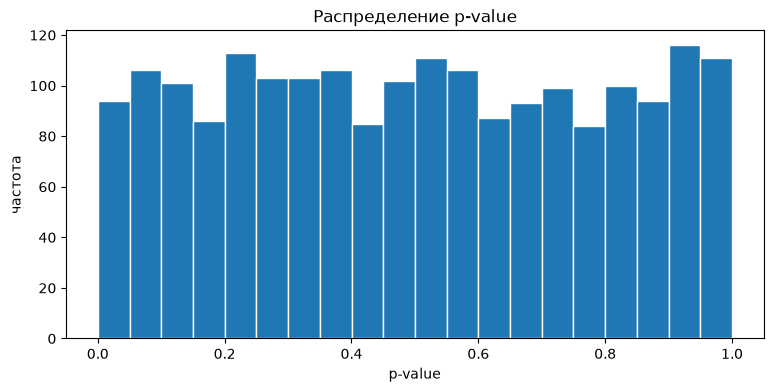

In [8]:
fig, ax = plt.subplots()
ax.hist(p_value, bins=20, edgecolor="white")
ax.set(title="Распределение p-value", xlabel="p-value", ylabel="частота")
plt.show()

Гистограмма плоская: p-value распределено **равномерно на отрезке [0, 1]**.

p-value — это вероятность получить статистику не менее экстремальную, чем наблюдаемая, если H0 верна, то есть $p = P(|T| \ge |t_{набл}|) = 1 - F(|t_{набл}|)$, где $F$ — функция распределения $|T|$ при H0. Когда H0 действительно верна, наблюдаемая $t$ сама взята из этого распределения, а значение функции распределения, применённой к своей же случайной величине, всегда равномерно: $P(p \le x) = x$ для любого $x$. Значит, любое значение p-value одинаково вероятно.

## Задача 5

In [40]:
rng = np.random.default_rng(SEED)
N_REP, n = 1000, 60

diff = np.empty(N_REP)
t_stat, p_value_t = np.empty(N_REP), np.empty(N_REP)
u_stat, p_value_u = np.empty(N_REP), np.empty(N_REP)
for i in range(N_REP):
    g1 = rng.normal(0, 1, n)
    g2 = rng.normal(1, 1, n)
    g2[:2] = -50
    diff[i] = g2.mean() - g1.mean()
    w = stats.ttest_ind(g2, g1, equal_var=False, alternative="two-sided")
    t_stat[i], p_value_t[i] = w.statistic, w.pvalue
    m = stats.mannwhitneyu(g1, g2, alternative="two-sided")
    u_stat[i], p_value_u[i] = m.statistic, m.pvalue

diff_mean = diff.mean()    
share_t = (p_value_t < alpha).mean()
share_u = (p_value_u < alpha).mean()
print(f"Средняя разница средних: {diff_mean:.3f}")
print(f"Доля отклонений нулевой гипотезы по t-тесту: {share_t:.3f}")
print(f"Доля отклонений нулевой гипотезы по U-тесту Манна-Уитни: {share_u:.3f}")

Средняя разница средних: -0.705
Доля отклонений нулевой гипотезы по t-тесту: 0.000
Доля отклонений нулевой гипотезы по U-тесту Манна-Уитни: 0.999


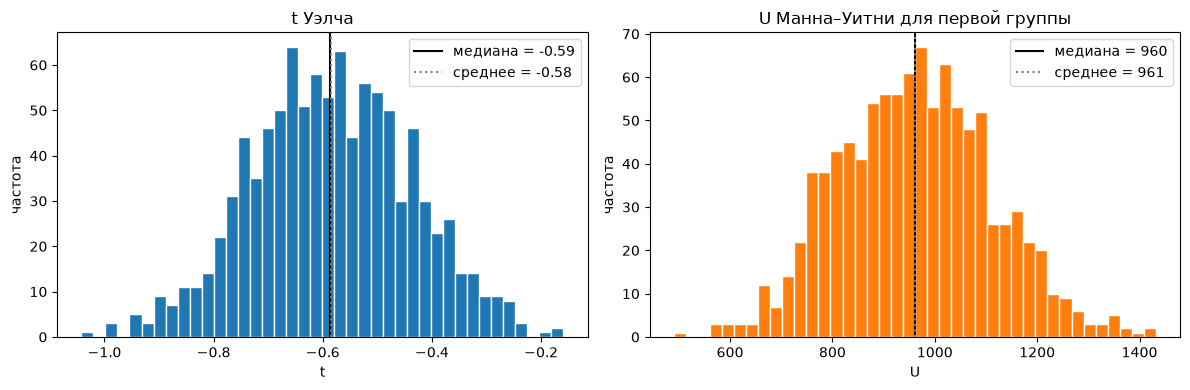

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(t_stat, bins=40, edgecolor="white")
axes[0].axvline(np.median(t_stat), color="black", ls="-", label=f"медиана = {np.median(t_stat):.2f}")
axes[0].axvline(t_stat.mean(), color="grey", ls=":", label=f"среднее = {t_stat.mean():.2f}")
axes[0].set(title="t Уэлча", xlabel="t", ylabel="частота")
axes[0].legend()

axes[1].hist(u_stat, bins=40, edgecolor="white", color="tab:orange")
axes[1].axvline(np.median(u_stat), color="black", ls="-", label=f"медиана = {np.median(u_stat):.0f}")
axes[1].axvline(u_stat.mean(), color="grey", ls=":", label=f"среднее = {u_stat.mean():.0f}")
axes[1].set(title="U Манна–Уитни для первой группы", xlabel="U", ylabel="частота")
axes[1].legend()
plt.tight_layout()
plt.show()

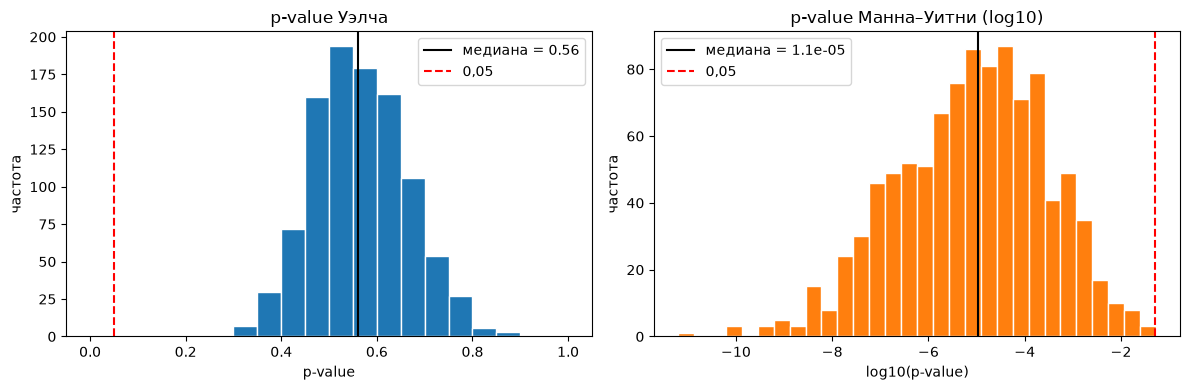

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
axes[0].hist(p_value_t, bins=20, range=(0, 1), edgecolor="white")
axes[0].axvline(np.median(p_value_t), color="black", label=f"медиана = {np.median(p_value_t):.2f}")
axes[0].axvline(alpha, color="red", ls="--", label="0,05")
axes[0].set(title="p-value Уэлча", xlabel="p-value", ylabel="частота")
axes[0].legend()

axes[1].hist(np.log10(p_value_u), bins=30, edgecolor="white", color="tab:orange")
axes[1].axvline(np.log10(np.median(p_value_u)), color="black", label=f"медиана = {np.median(p_value_u):.1e}")
axes[1].axvline(np.log10(alpha), color="red", ls="--", label="0,05")
axes[1].set(title="p-value Манна–Уитни (log10)", xlabel="log10(p-value)", ylabel="частота")
axes[1].legend()
plt.tight_layout()
plt.show()

Статистика Уэлча во всех повторах оказалась отрицательной и небольшой по модулю: значения лежат примерно от $-1{,}0$ до $-0{,}2$, медиана около $-0{,}59$, и ни одно не доходит до критической границы $\pm 1{,}96$. Знак получился обратным ожидаемому, потому что два значения $-50$ сдвигают среднее второй группы, и вместо истинной разницы $+1$ в среднем получается около $-0{,}7$. Соответственно, p-value Уэлча собраны в середине отрезка: медиана около $0{,}56$, а левее порога $0{,}05$ нет ни одного значения, так что критерий не отвергает H0 ни в одном из 1000 повторов.

Манн–Уитни ведёт себя противоположным образом. Статистика $U_1$ сосредоточена далеко слева от ожидаемого при H0 значения 1800 (всего 3600 пар) (медиана около 960, диапазон от 490 до 1430). Т. е. наблюдение первой группы оказывается больше наблюдения второй примерно в четверти пар, а не в половине. p-value при этом прижаты к нулю (медиана около $10^{-5}$), и H0 отвергается в 999 повторах из 1000. Таким образом, при одних и тех же данных два критерия приходят к разным выводам.

Расхождение объясняется тем, что t-тест опирается на среднее и дисперсию, а обе величины очень чувствительны к выбросам. Манн–Уитни работает с рангами, а насколько далеки выбросы не важно.

Важно, что критерии отвечают на разные вопросы. Уэлч проверяет равенство средних, а среднее второй группы при таких выбросах действительно оказывается ниже среднего первой. Манн–Уитни проверяет вероятность превосходства, то есть то, чаще ли случайное наблюдение второй группы больше случайного наблюдения первой. Поэтому из отвержения H0 критерием Манна–Уитни нельзя заключить, что среднее выросло.

## Задача 6

Гипотеза H0: средние двух групп равны, $\mu_2 - \mu_1 = 0$

In [9]:
rng = np.random.default_rng(SEED)

control = rng.normal(10.0, 2.0, 80)
test = rng.normal(10.8, 2.6, 75)

res = stats.ttest_ind(test, control, equal_var=False, alternative="two-sided")
ci = res.confidence_interval(confidence_level=0.95)
diff = test.mean() - control.mean()

print (f"diff = {diff:.3f}")
print(f"t = {res.statistic:.3f}, p-value = {res.pvalue:.4f}")
print(f"95% CI = [{ci.low:.3f}; {ci.high:.3f}]")

diff = 0.997
t = 2.860, p-value = 0.0050
95% CI = [0.307; 1.686]


Разница средних: $\approx 0{,}997$, 95% CI Уэлча **[0,307; 1,686]**.

$p = 0{,}005 < 0{,}05$, поэтому есть основание отвергнуть H0.
0 в интервал не попадает. 95% CI состоит ровно из тех значений эффекта, которые критерий Уэлча на уровне 5% не отвергает.
Самый маленький эффект, который ещё согласуется с данными, - около 0,307 (нижняя граница CI). Любая гипотеза $\mu_2 - \mu_1 = \delta$ с $\delta \ge 0{,}307$ (до 1,686) не отвергается.

## Задача 7

In [10]:
rng = np.random.default_rng(SEED)
N_BOOT = 2000

boot_diff = np.empty(N_BOOT)
for i in range(N_BOOT):
    control_b = rng.choice(control, size=control.size, replace=True)
    test_b = rng.choice(test, size=test.size, replace=True)
    boot_diff[i] = test_b.mean() - control_b.mean()

ci_boot = np.percentile(boot_diff, [2.5, 97.5])
share_le0 = (boot_diff <= 0).mean()

print(f"95% CI бутстрапа (перцентили 2,5 и 97,5): [{ci_boot[0]:.3f}; {ci_boot[1]:.3f}]")
print(f"95% CI Уэлча (задача 6): [{ci.low:.3f}; {ci.high:.3f}]")
print(f"\nДоля бутстрап-разниц <= 0: {share_le0:.4f}")

95% CI бутстрапа (перцентили 2,5 и 97,5): [0.287; 1.675]
95% CI Уэлча (задача 6): [0.307; 1.686]

Доля бутстрап-разниц <= 0: 0.0025


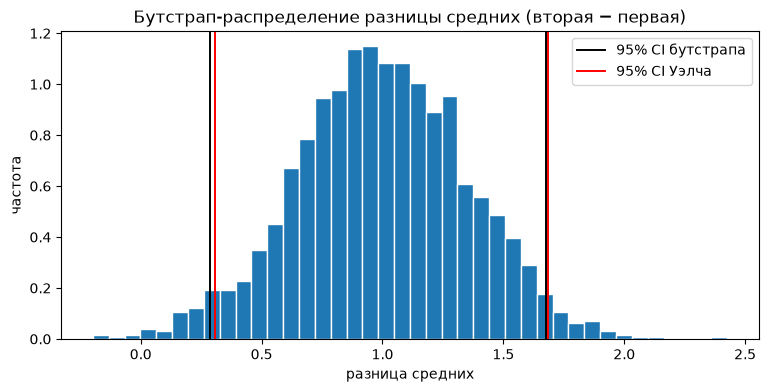

In [12]:
fig, ax = plt.subplots()
ax.hist(boot_diff, bins=40, edgecolor="white", density=True)

ax.axvline(ci_boot[0], color="black", linewidth=1.4, label="95% CI бутстрапа")
ax.axvline(ci_boot[1], color="black", linewidth=1.4)
ax.axvline(ci.low, color="red", linewidth=1.4, label="95% CI Уэлча")
ax.axvline(ci.high, color="red", linewidth=1.4)
ax.set_title("Бутстрап-распределение разницы средних (вторая − первая)")
ax.set_xlabel("разница средних")
ax.set_ylabel("частота")
ax.legend()
plt.show()

Границы бутстрапа $\approx [0{,}287;\ 1{,}675]$ почти совпадают с интервалом Уэлча $[0{,}307;\ 1{,}686]$. Оба метода говорят, что 0 в интервал не попадает.

Доля разниц $\le 0$ получилась около **0,0025**. Можно ли назвать её p-value? Строго говоря, нет. p-value по определению считается в предположении, что H0 верна. А бутстрап-выборки взяты из наблюдаемых данных, в которых разница равна 0,997. Это распределение оценки вокруг наблюдаемого эффекта, а не распределение статистики при H0.
Эта доля к тому же односторонняя: она смотрит только на хвост, который ниже нуля. Для двустороннего порога 5% её нужно удвоить. Удвоенная доля ($\approx 0{,}005$) здесь почти совпала с p-value Уэлча, но это совпадение из-за предположения симметрии распределения и для скошенных данных или малых выборок может нарушиться.